# AI Layoff Risk Predictor: Logistic Regression
**AI101 Mini-Project | Team 28** 

**Problem statement.** Predict whether an employee's layoff risk is **Low, Medium or High** from job, personal and AI-use features.

**Motivation.** As AI tools spread through workplaces, it helps to know which job traits go with higher layoff risk, for example routine tasks versus creative work.

**Task.** Multi-class classification with **Logistic Regression** (scikit-learn).

**Dataset.** Kaggle, **AI Impact on Jobs and Layoff Risk Dataset** . It is synthetic: 20,000 rows, 16 columns (9 numeric features, 6 categorical features and the label Layoff Risk)

In [2]:
%matplotlib inline
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, auc, classification_report,
                             f1_score, log_loss, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize

RANDOM_STATE = 42
DATA_PATH =  "ai-impact-jobs-layoff-risk-dataset.csv"  
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
TARGET = "Layoff_Risk"
LABELS = ["Low", "Medium", "High"]
COLORS = {"Low": "#2a9d8f", "Medium": "#e9c46a", "High": "#c0392b"}
pd.set_option("display.width", 200)

## 1. Load the data

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Rows: 20,000 | Columns: 16


,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         20000 non-null  int64
 1   Education_Level             20000 non-null  str  
 2   Years_of_Experience         20000 non-null  int64
 3   Industry                    20000 non-null  str  
 4   Job_Role                    20000 non-null  str  
 5   Company_Size                20000 non-null  str  
 6   Job_Level                   20000 non-null  str  
 7   Routine_Task_Percentage     20000 non-null  int64
 8   Creativity_Requirement      20000 non-null  int64
 9   Human_Interaction_Level     20000 non-null  int64
 10  AI_Adoption_Level           20000 non-null  str  
 11  Number_of_AI_Tools_Used     20000 non-null  int64
 12  AI_Usage_Hours_Per_Week     20000 non-null  int64
 13  Tasks_Automated_Percentage  20000 non-null  int64
 14  AI_Training_Hours

## 2. Data understanding with statistics

In [5]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols + [TARGET]]
print("Numeric features:", num_cols)
print("Categorical features:", cat_cols)


stats = df[num_cols].agg(["mean", "median", "std", "min", "max"]).T.round(2)
stats

Numeric features: ['Age', 'Years_of_Experience', 'Routine_Task_Percentage', 'Creativity_Requirement', 'Human_Interaction_Level', 'Number_of_AI_Tools_Used', 'AI_Usage_Hours_Per_Week', 'Tasks_Automated_Percentage', 'AI_Training_Hours']
Categorical features: ['Education_Level', 'Industry', 'Job_Role', 'Company_Size', 'Job_Level', 'AI_Adoption_Level']


,mean,median,std,min,max
Age,40.36,40.0,11.53,21.0,60.0
Years_of_Experience,7.27,7.0,4.72,0.0,32.0
Routine_Task_Percentage,51.89,52.0,24.44,10.0,94.0
Creativity_Requirement,47.79,48.0,26.10,0.0,100.0
Human_Interaction_Level,60.06,62.0,22.27,20.0,99.0
Number_of_AI_Tools_Used,2.46,2.0,2.10,0.0,10.0
AI_Usage_Hours_Per_Week,6.77,5.0,6.09,0.0,30.0
Tasks_Automated_Percentage,37.23,35.0,20.00,4.0,93.0
AI_Training_Hours,12.62,8.0,13.55,0.0,79.0


Layoff_Risk
Low       6602
Medium    6601
High      6797
Name: count, dtype: int64


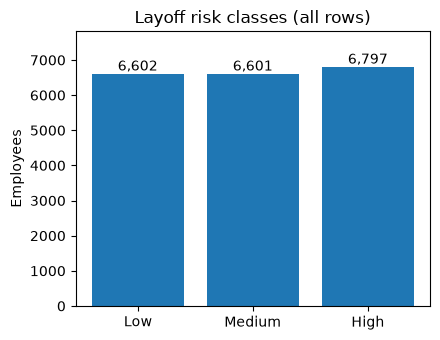

In [6]:
counts = df[TARGET].value_counts().reindex(LABELS)
print(counts)

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(counts.index, counts.values)
for i, v in enumerate(counts.values):
    ax.text(i, v + 100, f"{v:,}", ha="center")
ax.set(title="Layoff risk classes (all rows)", ylabel="Employees", ylim=(0, counts.max() * 1.15))
fig.tight_layout()
fig.savefig(OUT_DIR / "class_balance.png", dpi=150)
plt.show()

In [7]:
cov = df[num_cols].cov().round(1)
cov

,Age,Years_of_Experience,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours
Age,132.9,20.7,0.1,0.2,0.6,0.1,0.3,-0.1,-0.2
Years_of_Experience,20.7,22.3,-0.4,0.6,1.5,-0.0,-0.1,-0.4,-0.2
Routine_Task_Percentage,0.1,-0.4,597.2,-591.8,-9.1,33.9,100.1,435.0,198.0
Creativity_Requirement,0.2,0.6,-591.8,681.2,9.5,-33.8,-99.6,-431.8,-196.7
Human_Interaction_Level,0.6,1.5,-9.1,9.5,495.9,-0.3,-2.0,-4.7,-3.6
Number_of_AI_Tools_Used,0.1,-0.0,33.9,-33.8,-0.3,4.4,10.1,24.6,21.0
AI_Usage_Hours_Per_Week,0.3,-0.1,100.1,-99.6,-2.0,10.1,37.0,72.7,64.4
Tasks_Automated_Percentage,-0.1,-0.4,435.0,-431.8,-4.7,24.6,72.7,399.8,143.3
AI_Training_Hours,-0.2,-0.2,198.0,-196.7,-3.6,21.0,64.4,143.3,183.7


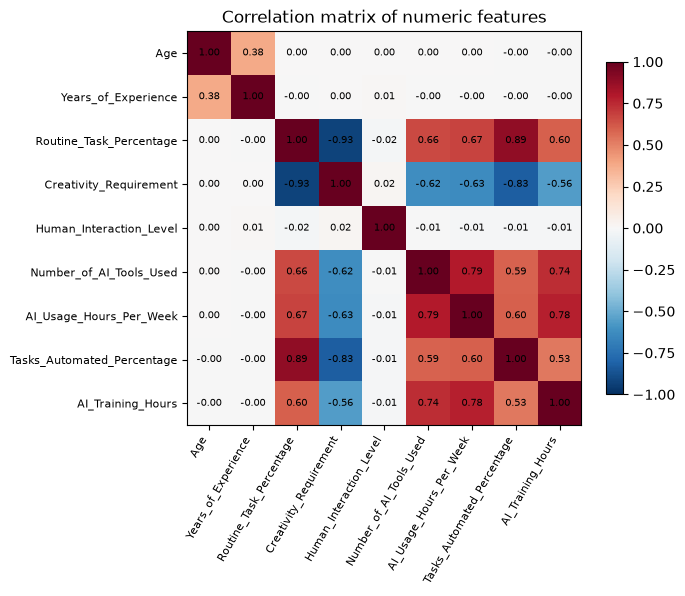

In [8]:
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(num_cols)), num_cols, fontsize=8)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix of numeric features")
fig.tight_layout()
fig.savefig(OUT_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

In [9]:
risk_score = df[TARGET].map({"Low": 0, "Medium": 1, "High": 2})
df[num_cols].corrwith(risk_score).round(2).sort_values()

Creativity_Requirement       -0.75
Human_Interaction_Level      -0.16
Years_of_Experience          -0.10
Age                          -0.04
AI_Training_Hours             0.43
AI_Usage_Hours_Per_Week       0.50
Number_of_AI_Tools_Used       0.50
Tasks_Automated_Percentage    0.75
Routine_Task_Percentage       0.78
dtype: float64

In [10]:
df.groupby(TARGET)[num_cols].mean().round(1).reindex(LABELS).T

Layoff_Risk,Low,Medium,High
Age,40.9,40.3,39.9
Years_of_Experience,7.9,7.3,6.7
Routine_Task_Percentage,28.5,51.3,75.2
Creativity_Requirement,71.9,48.3,23.8
Human_Interaction_Level,64.6,59.7,55.9
Number_of_AI_Tools_Used,1.3,2.3,3.8
AI_Usage_Hours_Per_Week,3.3,6.2,10.8
Tasks_Automated_Percentage,19.5,35.7,56.0
AI_Training_Hours,6.0,11.4,20.2


## 3. Preprocessing and train/test split
1. Check for missing values and duplicate rows, and drop them if present.
2. Split into **80% train / 20% test**, stratified on the label. We split *before* scaling so no test information leaks into training.
3. Scale numeric features with `StandardScaler` (normalisation to mean 0, standard deviation 1), fitted on the training set only.
4. One-hot encode the categorical features (the model needs numbers).
5. Feature selection: we keep all features. Logistic Regression uses L2 regularisation, which copes with correlated inputs.

In [11]:
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
df = df.drop_duplicates().dropna()

X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print("Class share in train:", y_train.value_counts(normalize=True).round(3).to_dict())

Missing values: 0 | Duplicate rows: 0
Train: (16000, 15) | Test: (4000, 15)
Class share in train: {'High': 0.34, 'Low': 0.33, 'Medium': 0.33}


## 4. Model, training functions and training plots
**Logistic Regression** gives each class a score (a weighted sum of the features) and turns the scores into probabilities with the softmax function. Training minimises the **log-loss** (cross-entropy)


In [ ]:
def training_curve_gd(X_tr, y_tr, X_te, y_te, max_epochs=100):
    clf = SGDClassifier(loss='log_loss', random_state=42)
    classes = np.unique(y_tr)
    rows = []
    
    for epoch in range(1, max_epochs + 1):
        clf.partial_fit(X_tr, y_tr, classes=classes)
        
        rows.append({
            "epoch": epoch,
            "train_loss": log_loss(y_tr, clf.predict_proba(X_tr), labels=classes),
            "test_loss": log_loss(y_te, clf.predict_proba(X_te), labels=classes),
            "train_acc": clf.score(X_tr, y_tr),
            "test_acc": clf.score(X_te, y_te)
        })
    return pd.DataFrame(rows)

history = training_curve_gd(X_train_t, y_train, X_test_t, y_test, max_epochs=100)
history